# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

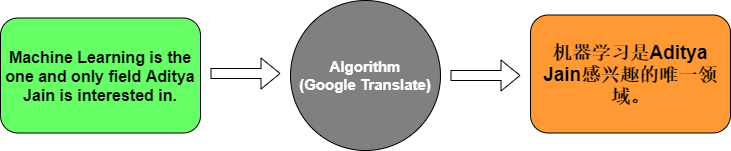

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step - accuracy: 0.0000e+00 - loss: 2.4850 - val_accuracy: 0.0000e+00 - val_loss: 2.4876
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5714 - loss: 2.4758 - val_accuracy: 0.0000e+00 - val_loss: 2.4895
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5714 - loss: 2.4665 - val_accuracy: 0.0000e+00 - val_loss: 2.4916
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5714 - loss: 2.4566 - val_accuracy: 0.0000e+00 - val_loss: 2.4938
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.5714 - loss: 2.4455 - val_accuracy: 0.0000e+00 - val_loss: 2.4963
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.5714 - loss: 2.4328 - val_accuracy: 0.0000e+00 - val_loss: 2.4991
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.5714 - loss: 2.4179 - val_accuracy: 0.0000e+00 - val_loss: 2.5022
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5714 - loss: 2.4005 - val_accurac

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1. Embedding layer:** Turns each word index (just an ID number like `5`) into a dense vector of learned numbers (here 64 values). Words with similar meaning end up with similar vectors, so the model works with meaning instead of arbitrary IDs.

**2. Encoder LSTM:** Reads the English sentence word by word and compresses it into one fixed-size vector (its final hidden state) that summarizes the meaning of the whole sentence. `RepeatVector` then copies this summary once for every French output position.

**3. Decoder LSTM:** Takes the repeated sentence summary and generates an output at every timestep (`return_sequences=True`), i.e. one hidden state per French word position. Each state is then passed to the Dense layer to predict the French word at that position.

**4. Why softmax:** At each position the model must pick one word out of the whole French vocabulary. Softmax turns the raw scores into probabilities that sum to 1, so we can take the most likely word with `argmax` and train with `sparse_categorical_crossentropy`.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [10]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

In [13]:
import kagglehub
import os
# Download latest version
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
Path to dataset files: /kaggle/input/language-translation-englishfrench


In [14]:
DATA_PATH = "eng_-french.csv"

df = pd.read_csv(
    os.path.join(path, DATA_PATH),
    encoding="latin1"
)
df.columns = ['english', 'french']
df = df.dropna().drop_duplicates()
print(df.shape)
df.head()

(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Coursâ¯!
2,Run!,Courezâ¯!
3,Who?,Qui ?
4,Wow!,Ãa alorsâ¯!


In [15]:
MAX_WORDS = 8
NUM_SAMPLES = 30000

df = df[(df['english'].str.split().str.len() <= MAX_WORDS) &
        (df['french'].str.split().str.len() <= MAX_WORDS)]
df = df.sample(n=min(NUM_SAMPLES, len(df)), random_state=42).reset_index(drop=True)

english_sentences = df['english'].str.lower().tolist()
french_sentences  = df['french'].str.lower().tolist()
print(len(english_sentences), 'sentence pairs')
print(english_sentences[0], '->', french_sentences[0])

30000 sentence pairs
i like that one better. -> je prã©fã¨re celle-lã .


In [16]:
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)

# keep French apostrophes (j'ai, c'est) by removing ' from the filters
tokenizer_frn = Tokenizer(filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n«»')
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

eng_vocab = len(tokenizer_eng.word_index) + 1
frn_vocab = len(tokenizer_frn.word_index) + 1

# Padding: input padded at the start (default), target padded at the end
eng_padded = pad_sequences(eng_sequences, padding='pre')
frn_padded = pad_sequences(frn_sequences, padding='post')
print('English vocab:', eng_vocab, '| French vocab:', frn_vocab)
print('eng_padded:', eng_padded.shape, '| frn_padded:', frn_padded.shape)

English vocab: 6920 | French vocab: 12635
eng_padded: (30000, 10) | frn_padded: (30000, 12)


In [17]:
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42)

# Same Encoder-Decoder LSTM as the lab, slightly bigger
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(eng_padded.shape[1],)),
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128),
    tf.keras.layers.LSTM(256),                                       # Encoder
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),               # length of French sentence
    tf.keras.layers.LSTM(256, return_sequences=True),                # Decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation='softmax'))
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 10, 128)        │       885,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 12, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 12, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 12, 12635)      │     3,247,195 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,052,507 (19.27 MB)

 Trainable params: 5,052,507 (19.27 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(eng_train, np.expand_dims(frn_train, -1),
                    epochs=30, batch_size=64, validation_split=0.1,
                    callbacks=[early_stop])

loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy:.4f}')

Epoch 1/30
338/338 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - accuracy: 0.5434 - loss: 3.7704 - val_accuracy: 0.5543 - val_loss: 3.3804
Epoch 2/30
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.5579 - loss: 3.2590 - val_accuracy: 0.5594 - val_loss: 3.2979
Epoch 3/30
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.5617 - loss: 3.1811 - val_accuracy: 0.5611 - val_loss: 3.2670
Epoch 4/30
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.5628 - loss: 3.1333 - val_accuracy: 0.5593 - val_loss: 3.2413
Epoch 5/30
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5635 - loss: 3.0970 - val_accuracy: 0.5615 - val_loss: 3.2277
Epoch 6/30
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.5641 - loss: 3.0619 - val_accuracy: 0.5632 - val_loss: 3.2032
Epoch 7/30
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5680 - loss: 2.9922 - val_accuracy: 0.5676 - val_loss: 3.1252
Epoch 8/30
338/338 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.5705 - loss: 2.9333 - 

In [19]:
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence.lower()])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1], padding='pre')
    predicted_sequence = model.predict(padded_sequence, verbose=0)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)
    return frn_tokenizer.sequences_to_texts(translated_sequence)[0]

# E-commerce style examples
for s in ["I like this shirt.", "The price is good.", "Where is my order?", "Thank you very much.", "It is too big."]:
    print(f'{s:25} -> {translate_sentence(s, model, tokenizer_eng, tokenizer_frn)}')

# Compare with real test sentences
idx_to_eng = tokenizer_eng.index_word
print()
for i in range(min(5, len(eng_test))):
    eng = ' '.join(idx_to_eng[t] for t in eng_test[i] if t != 0)
    real = tokenizer_frn.sequences_to_texts([frn_test[i]])[0]
    print(f'EN: {eng}\nTrue: {real}\nPred: {translate_sentence(eng, model, tokenizer_eng, tokenizer_frn)}\n')

I like this shirt.        -> j'aime la la
The price is good.        -> le vie est trã¨s
Where is my order?        -> oã¹ est ton
Thank you very much.      -> j'ai un prudent
It is too big.            -> c'est fait bon bon

EN: tom was worried about that
True: tom ã©tait inquiet ã  propos de cela
Pred: tom est toujours de

EN: i didn't know about that until quite recently
True: je n'en savais rien jusqu'il y a peu
Pred: je ne pas pas de les les

EN: i'm only here because of you
True: je suis ici seulement ã  cause de toi
Pred: je suis pas pas vous vous vous

EN: tom is three years older than you
True: tom est trois ans plus vieux que vous
Pred: tom a plus plus plus que moi moi

EN: they have come
True: elles sont arrivã©es
Pred: elles l'ont

